# Práctica 2 — Filtrado colaborativo: predicción de valoraciones de restaurantes

**Objetivo:** predecir las 40.000 valoraciones que se han ocultado (con un `99`) en `recommendation_dataset.csv`
y guardarlas en `resultats.csv`. La calidad se mide con el **MAE** (error absoluto medio): cuántos puntos nos
equivocamos, de media, en cada predicción. Cuanto más bajo, mejor (para aprobar: MAE < 3,77).

**Cómo está organizado el notebook:**

1. **Carga de datos**: leemos la matriz usuarios × restaurantes.
2. **Exploración**: unos números para conocer los datos.
3. **Validación propia**: apartamos 40.000 valoraciones que sí conocemos para poder medir cada método.
4. **Escalera de métodos**, de más simple a más elaborado: media global → media de cada restaurante →
   media de cada usuario → sesgos de usuario y restaurante → **k-NN por ítems** (el método final).
5. **Resumen** de los MAE obtenidos.
6. **Predicción final** con todos los datos y escritura de `resultats.csv`.
7. **Comprobación oficial** con el script `compute_mae.py` del enunciado.

Las celdas que empiezan por `# Comprobaciones` contienen `assert`: si algo no es como esperamos, el notebook se
detiene ahí. Sirven para demostrar que cada pieza hace lo que dice.

In [1]:
import os
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Carpeta con los ficheros del enunciado (ruta relativa: el notebook se ejecuta desde la carpeta P2_SIO)
RUTA_DATOS = "ConjuntDades_P2"
SEMILLA = 42          # semilla fija: así todos obtenemos exactamente los mismos resultados
N_VALIDACION = 40000  # cuántas valoraciones conocidas apartamos para validar (las mismas que tiene el test)

## 1. Carga de datos

El fichero `recommendation_dataset.csv` es una matriz de **73.421 usuarios (filas) × 100 restaurantes (columnas)**,
separada por `;`. Cada celda es la nota (entre −10 y 10) que un usuario ha puesto a un restaurante, o `99` si no la
conocemos.

- Guardamos la matriz como un array de numpy `R` de tipo **`float32`** (ocupa la mitad que `float64` y la precisión
  sobra para notas con 2 decimales).
- Los `99` los convertimos en **`NaN`** ("Not a Number"), la forma estándar de numpy de marcar un hueco. Así nunca se
  confunden con una nota real y funciones como `np.nanmean` los ignoran automáticamente.

`template.csv` nos dice **qué** 40.000 celdas hay que predecir (usuario y restaurante). Las traducimos a posiciones
(fila, columna) de `R` para poder trabajar con índices numéricos.

In [2]:
def cargar_matriz(ruta):
    """Lee el CSV de valoraciones y devuelve (R, usuarios, restaurantes).

    R: matriz float32 (n_usuarios, n_restaurantes) con NaN donde la valoración es desconocida.
    usuarios / restaurantes: nombres de filas ("User1", ...) y columnas ("Restaurant1", ...).
    """
    df = pd.read_csv(ruta, sep=";", index_col=0)   # la primera columna (User1, User2, ...) es el índice
    R = df.to_numpy(dtype=np.float32)
    R[R == 99] = np.nan                            # 99 = desconocido  ->  NaN
    return R, df.index.to_numpy(), df.columns.to_numpy()


def cargar_posiciones(ruta, usuarios, restaurantes):
    """Lee template.csv y traduce cada par (usuario, restaurante) a su (fila, columna) dentro de R.

    Devuelve (plantilla, filas_u, cols_i): la tabla original (para escribir luego el resultado en el
    mismo orden) y dos arrays de enteros con las posiciones a predecir.
    """
    # Cada línea es "User25287;Restaurant31;" -> la tercera columna viene vacía y la descartamos
    plantilla = pd.read_csv(ruta, sep=";", header=None, names=["usuario", "restaurante", "vacia"])
    plantilla = plantilla.drop(columns="vacia")
    # Diccionarios nombre -> posición, p. ej. "User1" -> 0, "Restaurant31" -> 30
    fila_de = {nombre: k for k, nombre in enumerate(usuarios)}
    col_de = {nombre: k for k, nombre in enumerate(restaurantes)}
    filas_u = plantilla["usuario"].map(fila_de).to_numpy()
    cols_i = plantilla["restaurante"].map(col_de).to_numpy()
    return plantilla, filas_u, cols_i

In [3]:
R, usuarios, restaurantes = cargar_matriz(f"{RUTA_DATOS}/recommendation_dataset.csv")
plantilla, filas_u, cols_i = cargar_posiciones(f"{RUTA_DATOS}/template.csv", usuarios, restaurantes)
print(f"Matriz R: {R.shape[0]:,} usuarios x {R.shape[1]} restaurantes")
print(f"Posiciones a predecir: {len(plantilla):,}")

Matriz R: 73,421 usuarios x 100 restaurantes
Posiciones a predecir: 40,000


In [4]:
# Comprobaciones de la carga
assert R.shape == (73421, 100) and R.dtype == np.float32
assert abs(np.isfinite(R).mean() - 0.558) < 0.001          # densidad del enunciado
assert np.nanmin(R) >= -10 and np.nanmax(R) <= 10           # no queda ningún 99
assert len(plantilla) == 40000 and len(filas_u) == len(cols_i) == 40000
assert np.isnan(R[filas_u, cols_i]).all()                   # las celdas a predecir son desconocidas
print("Carga correcta")

Carga correcta


## 2. Exploración breve

Antes de predecir nada, miramos cuántas valoraciones hay y cómo se reparten.

In [5]:
conocidas = np.isfinite(R)                    # True donde conocemos la valoración
por_usuario = conocidas.sum(axis=1)           # nº de valoraciones de cada usuario
por_restaurante = conocidas.sum(axis=0)       # nº de valoraciones de cada restaurante

print(f"Densidad: {conocidas.mean():.3f}  ({conocidas.sum():,} valoraciones conocidas)")
print(f"Valoraciones por usuario:     mín {por_usuario.min()}, mediana {np.median(por_usuario):.0f}, máx {por_usuario.max()}")
print(f"Valoraciones por restaurante: mín {por_restaurante.min():,}, máx {por_restaurante.max():,}")
print(f"Media global de las notas: {np.nanmean(R):.3f}")

Densidad: 0.558  (4,096,360 valoraciones conocidas)
Valoraciones por usuario:     mín 14, mediana 52, máx 100
Valoraciones por restaurante: mín 18,338, máx 72,721
Media global de las notas: 0.742


**Qué nos dicen estos números:**

- Conocemos algo más de la mitad de la matriz (≈ 55,8 %, como dice el enunciado).
- **Todos los usuarios tienen al menos 14 valoraciones**, así que siempre podremos calcular algo propio de cada usuario.
- **Cada restaurante tiene miles de valoraciones**: las estadísticas por restaurante son muy fiables. Por eso
  compararemos restaurantes entre sí (k-NN por ítems) en lugar de comparar usuarios.
- Además, comparar usuarios entre sí (k-NN por usuarios) exigiría una matriz de similitudes de 73.421 × 73.421, unos
  **21,6 GB** en `float32`, que no cabe en la memoria de un portátil. La de restaurantes es de solo 100 × 100.
- La media global es ligeramente positiva: en conjunto, los usuarios puntúan un poco por encima de 0.

## 3. Validación propia

Cada método tiene parámetros que hay que elegir (por ejemplo, cuántos vecinos usar). Para elegirlos necesitamos medir el
MAE, pero **no queremos elegirlos mirando el test oficial** (`target_recommendations.csv`): sería como preparar un
examen mirando las respuestas, y el MAE que obtendríamos sería engañosamente optimista.

Por eso nos fabricamos un **"examen de práctica"**:

1. Elegimos al azar 40.000 valoraciones que **sí conocemos** (tantas como tiene el test oficial).
2. Las ocultamos (las ponemos a `NaN`) en una copia de la matriz: `R_train`. Todos los métodos aprenderán solo de `R_train`.
3. Predecimos esas 40.000 celdas y comparamos con sus valores reales, que tenemos guardados en `val_real`.

El **MAE** (error absoluto medio) es:

$$\text{MAE} = \frac{1}{n}\sum_{k=1}^{n} |\text{real}_k - \text{predicción}_k|$$

El test oficial solo se usa **una vez, al final** (sección 7), para obtener el MAE que entregamos.

In [6]:
def crear_validacion(R, n=N_VALIDACION, semilla=SEMILLA):
    """Aparta n valoraciones conocidas, elegidas al azar, para usarlas como "examen de práctica".

    Devuelve (R_train, val_u, val_i, val_real):
      R_train   copia de R con esas n celdas puestas a NaN (con ella aprenderán los métodos)
      val_u     filas (usuarios) de las celdas apartadas
      val_i     columnas (restaurantes) de las celdas apartadas
      val_real  sus valores reales, para compararlos con nuestras predicciones
    """
    generador = np.random.default_rng(semilla)
    filas, cols = np.nonzero(np.isfinite(R))                   # posiciones de todas las notas conocidas
    elegidas = generador.choice(len(filas), size=n, replace=False)
    val_u, val_i = filas[elegidas], cols[elegidas]
    val_real = R[val_u, val_i].copy()
    R_train = R.copy()                                         # copia: la R original no se modifica
    R_train[val_u, val_i] = np.nan
    return R_train, val_u, val_i, val_real


def mae(pred, real):
    """Error absoluto medio: media de |predicción - valor real|."""
    return float(np.mean(np.abs(pred - real)))

In [7]:
R_train, val_u, val_i, val_real = crear_validacion(R)
resultados = {}   # aquí guardaremos el MAE de validación de cada método: {"nombre del método": MAE}
print(f"Valoraciones para entrenar: {np.isfinite(R_train).sum():,}   |   para validar: {len(val_real):,}")

Valoraciones para entrenar: 4,056,360   |   para validar: 40,000


In [8]:
# Comprobaciones de la validación
assert mae(np.array([1., -2.]), np.array([0., 0.])) == 1.5   # (|1-0| + |-2-0|) / 2
assert np.isnan(R_train[val_u, val_i]).all()                 # ocultas en entrenamiento
assert np.isfinite(R[val_u, val_i]).all()                    # R original intacta
assert np.isfinite(R_train).sum() == np.isfinite(R).sum() - N_VALIDACION
# Misma semilla -> mismas celdas. (Esta llamada crea una copia temporal de R que se libera al acabar la comprobación.)
assert np.array_equal(crear_validacion(R)[1], val_u)
print("Validación correcta")

Validación correcta


## 4. Escalera de métodos

Probamos métodos de más simple a más elaborado. Todos siguen el mismo patrón:

1. Aprenden **solo de `R_train`**.
2. Predicen las 40.000 celdas de validación `(val_u, val_i)`.
3. Recortan la predicción al rango válido **[−10, 10]** con `np.clip` (predecir fuera del rango solo puede empeorar el error).
4. Calculan el MAE y lo guardan en `resultados`.

### 4.1 Media global

La idea más simple: predecir para **todas** las celdas la misma nota, la media de todas las valoraciones conocidas.
Es el método de referencia del enunciado (MAE 4,43 en el test oficial), así que también nos sirve para comprobar
que nuestra validación se comporta como el test.

In [9]:
media_global = np.nanmean(R_train)                          # nanmean ignora los NaN (huecos)
pred = np.full(len(val_real), media_global, dtype=np.float32)
pred = np.clip(pred, -10, 10)
assert np.isfinite(pred).all()                              # ninguna predicción puede quedar vacía

resultados["Media global"] = mae(pred, val_real)
print(f"Media global = {media_global:.3f}  ->  MAE validación = {resultados['Media global']:.3f}")

Media global = 0.742  ->  MAE validación = 4.432


### 4.2 Media de cada restaurante

Cada restaurante tiene su propia "fama": predecimos para cada celda la nota media que ha recibido **ese restaurante**
(la media de su columna).

In [10]:
media_restaurante = np.nanmean(R_train, axis=0)             # una media por columna (restaurante)
# Si algún restaurante no tuviera ninguna nota, usaríamos la media global
media_restaurante = np.where(np.isfinite(media_restaurante), media_restaurante, media_global)
pred = np.clip(media_restaurante[val_i], -10, 10)
assert np.isfinite(pred).all()

resultados["Media restaurante"] = mae(pred, val_real)
print(f"MAE validación = {resultados['Media restaurante']:.3f}")

MAE validación = 4.192


### 4.3 Media de cada usuario

Ahora al revés: cada usuario tiene su forma de puntuar (hay usuarios generosos y otros muy exigentes). Predecimos
para cada celda la nota media que ha puesto **ese usuario** (la media de su fila).

In [11]:
media_usuario = np.nanmean(R_train, axis=1)                 # una media por fila (usuario)
# Si algún usuario se hubiese quedado sin notas al apartar la validación, usaríamos la media global
media_usuario = np.where(np.isfinite(media_usuario), media_usuario, media_global)
pred = np.clip(media_usuario[val_u], -10, 10)
assert np.isfinite(pred).all()

resultados["Media usuario"] = mae(pred, val_real)
print(f"MAE validación = {resultados['Media usuario']:.3f}")

MAE validación = 3.738


La media de cada usuario funciona **bastante mejor** que la de cada restaurante: lo que más explica una nota es
**quién** la pone. Aun así, ambas informaciones son útiles, y el siguiente paso es combinarlas.

In [12]:
# Comprobaciones de los métodos de medias
assert 4.40 < resultados["Media global"] < 4.46     # el enunciado dice que este método da 4,43
assert "Media restaurante" in resultados and "Media usuario" in resultados
print("Medias correctas")

Medias correctas


### 4.4 Sesgos de usuario y de restaurante

Combinamos las dos ideas anteriores. Modelamos cada nota como:

$$\hat r_{ui} = \mu + b_u + b_i$$

- $\mu$: media global de todas las notas.
- $b_u$: **sesgo del usuario** $u$, es decir, cuánto puntúa por encima (o por debajo) de la media. Un usuario generoso tiene $b_u > 0$.
- $b_i$: **sesgo del restaurante** $i$, es decir, cuánto mejor (o peor) valorado está que la media, **una vez descontado** quién lo ha puntuado.

**¿Por qué no usar directamente la media de usuario y la de restaurante?** Porque se pisan entre sí: si un restaurante
lo han puntuado sobre todo usuarios generosos, su media sale inflada. Por eso calculamos los sesgos **alternando**:

$$b_i = \frac{\sum_{u \in U_i} (r_{ui} - \mu - b_u)}{|U_i| + \lambda_i} \qquad\qquad b_u = \frac{\sum_{i \in I_u} (r_{ui} - \mu - b_i)}{|I_u| + \lambda_u}$$

donde $U_i$ son los usuarios que han valorado el restaurante $i$, e $I_u$ los restaurantes que ha valorado el usuario $u$.
Repetimos los dos pasos unas cuantas veces (10) y los valores se estabilizan.

**¿Qué es λ (regularización)?** Es un número que se suma al denominador para **desconfiar de quien tiene pocas notas**.
Ejemplo: un usuario con solo 3 notas, que de media está +6 por encima de μ. Sin λ, su sesgo sería $18/3 = 6$. Con
$\lambda_u = 5$, sería $18/(3+5) = 2{,}25$, más prudente. A un usuario con 90 notas, λ = 5 apenas le afecta. El mejor
valor de λ lo elegimos con la validación.

In [13]:
def calcular_sesgos(R, lam_u, lam_i, n_iter=10):
    """Calcula la media global mu y los sesgos regularizados de usuarios (b_u) y restaurantes (b_i).

    Modelo: nota(u, i) ≈ mu + b_u[u] + b_i[i]. Se alterna n_iter veces: primero se recalcula b_i
    con b_u fijo y después b_u con b_i fijo. lam_u / lam_i son las regularizaciones λ.
    """
    conocida = np.isfinite(R)                                   # máscara: True donde hay nota
    mu = float(np.nanmean(R))
    D = np.where(conocida, R - mu, 0).astype(np.float32)        # r_ui - mu (0 en los huecos, así no suman)
    n_u = conocida.sum(axis=1)                                  # nº de notas de cada usuario   |I_u|
    n_i = conocida.sum(axis=0)                                  # nº de notas de cada restaurante |U_i|
    b_u = np.zeros(R.shape[0], np.float32)
    b_i = np.zeros(R.shape[1], np.float32)

    for _ in range(n_iter):
        # b_i: suma de (r_ui - mu - b_u) de los usuarios que valoraron i, dividida por |U_i| + λ_i
        suma_i = (D - b_u[:, None] * conocida).sum(axis=0)
        b_i = np.divide(suma_i, n_i + lam_i, out=np.zeros_like(b_i), where=(n_i + lam_i) > 0)
        # b_u: suma de (r_ui - mu - b_i) de los restaurantes que valoró u, dividida por |I_u| + λ_u
        suma_u = (D - b_i[None, :] * conocida).sum(axis=1)
        b_u = np.divide(suma_u, n_u + lam_u, out=np.zeros_like(b_u), where=(n_u + lam_u) > 0)
        # (where=... evita dividir por 0: quien no tiene ninguna nota se queda con sesgo 0)

    return mu, b_u, b_i

In [14]:
# Comprobaciones de calcular_sesgos con un ejemplo pequeño que podemos razonar a mano:
# construimos notas que son EXACTAMENTE "1 + sesgo del usuario + sesgo del restaurante".
a = np.array([0, 1, -1, 2], np.float32)       # sesgos de 4 usuarios
c = np.array([0.5, -0.5, 0], np.float32)      # sesgos de 3 restaurantes
R_ej = (1 + a[:, None] + c[None, :]).astype(np.float32)
mu_ej, bu_ej, bi_ej = calcular_sesgos(R_ej, 0, 0, n_iter=20)
assert np.allclose(mu_ej + bu_ej[:, None] + bi_ej[None, :], R_ej, atol=1e-4)   # debe reconstruir las notas

R_ej2 = np.vstack([R_ej, np.full((1, 3), np.nan, np.float32)])  # añadimos un usuario sin ninguna valoración
assert np.isfinite(calcular_sesgos(R_ej2, 0, 0)[1]).all()       # su sesgo debe ser 0, no NaN
print("calcular_sesgos correcta")

calcular_sesgos correcta


**Elección de λ.** Probamos varias combinaciones de $\lambda_u$ y $\lambda_i$ sobre la validación y nos quedamos con la
de menor MAE. La tabla muestra el MAE de cada combinación (filas: $\lambda_u$, columnas: $\lambda_i$).

In [15]:
lams_u = [0, 2, 5, 10, 20]
lams_i = [0, 25, 100]
tabla_sesgos = pd.DataFrame(index=lams_u, columns=lams_i, dtype=float)
tabla_sesgos.index.name, tabla_sesgos.columns.name = "λ usuario", "λ restaurante"

for lam_u in lams_u:
    for lam_i in lams_i:
        mu, b_u, b_i = calcular_sesgos(R_train, lam_u, lam_i)
        pred = np.clip(mu + b_u[val_u] + b_i[val_i], -10, 10)
        tabla_sesgos.loc[lam_u, lam_i] = mae(pred, val_real)

display(tabla_sesgos.round(4))

mejor_lam_u, mejor_lam_i = tabla_sesgos.stack().idxmin()      # posición (fila, columna) del MAE mínimo
resultados["Sesgos"] = float(tabla_sesgos.loc[mejor_lam_u, mejor_lam_i])
print(f"Mejor combinación: λ_u = {mejor_lam_u}, λ_i = {mejor_lam_i}  ->  MAE validación = {resultados['Sesgos']:.3f}")

λ restaurante,0,25,100
λ usuario,,,
0,3.4689,3.4689,3.4690
2,3.4767,3.4767,3.4768
5,3.4908,3.4908,3.4909
10,3.5164,3.5165,3.5166
20,3.5669,3.5670,3.5671


Mejor combinación: λ_u = 0, λ_i = 0  ->  MAE validación = 3.469


**Resultado:** el mejor valor es **λ = 0**, es decir, aquí la regularización no ayuda (cuanto mayor es $\lambda_u$, peor).
Tiene sentido: todos los usuarios tienen al menos 12 notas en `R_train` (14 en la matriz completa) y cada restaurante tiene miles, así que sus sesgos ya son
fiables sin necesidad de "encogerlos". Aun así, ya mejoramos claramente la media de usuario, porque ahora tenemos en
cuenta **a la vez** quién puntúa y qué restaurante es.

In [16]:
# Comprobaciones de los sesgos: deben mejorar a la media de usuario
assert resultados["Sesgos"] < resultados["Media usuario"] and resultados["Sesgos"] < 3.55
print("Sesgos correctos")

Sesgos correctos


### 4.5 k-NN por ítems (método final)

Los sesgos dicen si un usuario es generoso y si un restaurante es bueno en general, pero **no capturan gustos
concretos**: a alguien le pueden encantar los restaurantes japoneses aunque en general puntúe bajo. El k-NN por ítems
aprovecha esto: *"si a este usuario le gustaron los restaurantes **parecidos** a este, probablemente también le
gustará este"*.

**Paso 1: residuos.** Primero quitamos de cada nota lo que ya explican los sesgos:

$$e_{ui} = r_{ui} - (\mu + b_u + b_i)$$

Un residuo positivo significa que al usuario le gustó ese restaurante **más de lo esperado**. Trabajamos con residuos
para que la similitud mida **gustos** y no si el usuario es generoso.

**Paso 2: similitud entre restaurantes.** Dos restaurantes $i$ y $j$ son parecidos si los usuarios que han valorado
ambos tienden a tener residuos del mismo signo en los dos. Lo medimos con la **correlación de Pearson** sobre los residuos,
usando solo los usuarios en común $U_{ij}$:

$$s_{ij} = \frac{\sum_{u \in U_{ij}} e_{ui}\, e_{uj}}{\sqrt{\sum_{u \in U_{ij}} e_{ui}^2 \cdot \sum_{u \in U_{ij}} e_{uj}^2}}$$

Vale entre −1 (gustos opuestos) y +1 (gustos idénticos). Como solo hay 100 restaurantes, la matriz de similitudes es de
100 × 100 y se calcula **una sola vez** con productos de matrices.

**¿Y la resta de la media?** La correlación de Pearson habitual resta a cada nota la media del restaurante antes de
multiplicar. Aquí no hace falta: los residuos $e_{ui}$ ya tienen media prácticamente 0 en cada restaurante (eso es
justo lo que quita $b_i$), así que la fórmula de Pearson se reduce a la de arriba. Esta variante se conoce como Pearson
sobre residuos (*pearson-baseline*).

> *Probamos también a "encoger" hacia 0 las similitudes calculadas con pocos usuarios en común, multiplicándolas por
> $n_{ij}/(n_{ij}+\text{encogimiento})$, con encogimiento ∈ {25, 50, 100, 200}. **No mejoró el MAE** (las diferencias fueron menores de
> 0,0001): cada par de restaurantes comparte casi 14.000 usuarios como mínimo (13.843 en `R_train`), así que las similitudes ya son fiables. Lo descartamos
> para que el método sea más simple.*

**Paso 3: predicción.** Para predecir la nota del usuario $u$ al restaurante $i$:

1. De los restaurantes que $u$ **sí ha valorado**, cogemos los $k$ más parecidos a $i$ (sus "vecinos").
2. Hacemos la media de los residuos de $u$ en esos vecinos, **ponderada por la similitud** (solo cuentan las similitudes positivas).
3. Se la sumamos a la predicción de los sesgos:

$$\hat r_{ui} = \mu + b_u + b_i + \frac{\sum_{j \in N_k(i;u)} s^+_{ij}\, e_{uj}}{\sum_{j \in N_k(i;u)} s^+_{ij}} \qquad \text{con } s^+_{ij} = \max(0,\, s_{ij})$$

donde $N_k(i;u)$ son los $k$ restaurantes valorados por $u$ más parecidos a $i$. Con $s^+_{ij}$, un vecino con similitud
negativa pesa 0 (no cuenta).

Si el usuario no tiene ningún vecino con similitud positiva, la predicción es simplemente la de los sesgos.

In [17]:
def calcular_residuos(R, mu, b_u, b_i):
    """Devuelve (E, M): E = r_ui - (mu + b_u + b_i) donde hay nota y 0 en los huecos; M = máscara de notas conocidas."""
    M = np.isfinite(R)
    E = np.where(M, R - (mu + b_u[:, None] + b_i[None, :]), 0).astype(np.float32)
    return E, M


def calcular_similitudes(E, M):
    """Matriz (n_restaurantes x n_restaurantes) de similitudes de Pearson sobre los residuos.

    Como E vale 0 en los huecos, los productos de matrices solo suman sobre usuarios que han valorado ambos restaurantes.
    """
    numerador = E.T @ E                                       # [i, j] = Σ e_ui · e_uj   (usuarios en común)
    cuadrados = (E ** 2).T @ M.astype(np.float32)             # [i, j] = Σ e_ui²  de los usuarios que valoraron i y j
    denominador = np.sqrt(cuadrados * cuadrados.T) + 1e-9     # + 1e-9 para no dividir nunca por 0
    S = numerador / denominador
    np.fill_diagonal(S, 0)                       # un restaurante no es vecino de sí mismo
    return S.astype(np.float32)


def predecir_knn(E, M, S, mu, b_u, b_i, u, i, k):
    """Predice la nota de cada par (u[n], i[n]) con k-NN por ítems sobre residuos. Devuelve un array recortado a [-10, 10]."""
    base = mu + b_u[u] + b_i[i]                  # predicción de los sesgos (sección 4.4)
    sim = np.where(M[u], S[i], -np.inf)          # similitud con cada restaurante; -inf si el usuario no lo ha valorado
    k = min(k, S.shape[0])
    vecinos = np.argpartition(-sim, k - 1, axis=1)[:, :k]    # índices de los k más similares de cada fila
    sim_vecinos = np.take_along_axis(sim, vecinos, axis=1)
    res_vecinos = np.take_along_axis(E[u], vecinos, axis=1)  # residuos del usuario en esos vecinos
    pesos = np.maximum(sim_vecinos, 0)           # solo similitudes positivas (los -inf se quedan en 0)
    suma_pesos = pesos.sum(axis=1)
    # Media ponderada de los residuos; si la suma de pesos es 0 (sin vecinos útiles), el ajuste es 0
    ajuste = np.divide((pesos * res_vecinos).sum(axis=1), suma_pesos,
                       out=np.zeros_like(suma_pesos), where=suma_pesos > 0)
    return np.clip(base + ajuste, -10, 10).astype(np.float32)

In [18]:
# Comprobaciones del k-NN con un ejemplo de 2 usuarios x 3 restaurantes, calculable a mano.
# El usuario 1 ha valorado los restaurantes 0 (residuo +1) y 2 (residuo -1); queremos predecir el restaurante 1.
E_ej = np.array([[0, 0, 0], [1, 0, -1]], np.float32)
M_ej = np.array([[False, True, False], [True, False, True]])
S_ej = np.array([[0, .8, .2], [.8, 0, .5], [.2, .5, 0]], np.float32)   # similitud(1,0) = 0.8, similitud(1,2) = 0.5
cero_u, cero_i = np.zeros(2, np.float32), np.zeros(3, np.float32)
u1, i1 = np.array([1]), np.array([1])
# k=2: media ponderada (0.8·(+1) + 0.5·(-1)) / (0.8 + 0.5) = 0.3 / 1.3
assert np.isclose(predecir_knn(E_ej, M_ej, S_ej, 0., cero_u, cero_i, u1, i1, k=2)[0], 0.3 / 1.3)
# k=1: solo el vecino más parecido (restaurante 0, residuo +1)
assert np.isclose(predecir_knn(E_ej, M_ej, S_ej, 0., cero_u, cero_i, u1, i1, k=1)[0], 1.0)
# Sin vecinos con similitud positiva -> la predicción es solo la base mu + b_u + b_i (= 2)
S_neg = -np.abs(S_ej)
assert np.isclose(predecir_knn(E_ej, M_ej, S_neg, 2., cero_u, cero_i, u1, i1, k=2)[0], 2.0)
# La predicción nunca se sale del rango [-10, 10]
assert predecir_knn(E_ej, M_ej, S_ej, 9.5, cero_u + 1, cero_i, u1, i1, k=2)[0] <= 10
# Similitud con un ejemplo de 3 usuarios x 2 restaurantes, calculable a mano. El usuario 1 NO valoró el restaurante 1,
# así que solo cuentan los usuarios 0 y 2 (los que valoraron ambos):
#   numerador = 1·2 + 2·1 = 4;   Σ e_u0² = 1² + 2² = 5;   Σ e_u1² = 2² + 1² = 5;   s_01 = 4 / √(5·5) = 0,8
# (si por error incluyéramos al usuario 1 en Σ e_u0², saldría 4 / √(14·5) ≈ 0,48)
E_sim = np.array([[1, 2], [3, 0], [2, 1]], np.float32)
M_sim = np.array([[True, True], [True, False], [True, True]])
S_sim = calcular_similitudes(E_sim, M_sim)
assert np.isclose(S_sim[0, 1], 0.8) and np.isclose(S_sim[1, 0], 0.8) and np.all(np.diag(S_sim) == 0)
print("k-NN correcto")

k-NN correcto


**Elección de k.** Calculamos los sesgos, los residuos y la matriz de similitudes **una sola vez** (con los mejores λ)
y probamos varios valores de k, el número de vecinos.

- Con k pequeño usamos solo los restaurantes muy parecidos, pero la media es "ruidosa" porque se basa en pocas notas.
- Con k grande la media es más estable, pero se cuelan restaurantes poco parecidos.

In [19]:
mu, b_u, b_i = calcular_sesgos(R_train, mejor_lam_u, mejor_lam_i)
E, M = calcular_residuos(R_train, mu, b_u, b_i)
S = calcular_similitudes(E, M)

valores_k = [5, 10, 15, 20, 30, 40, 60, 100]
mae_por_k = pd.Series(index=valores_k, dtype=float, name="MAE validación")
mae_por_k.index.name = "k"
for k in valores_k:
    pred = predecir_knn(E, M, S, mu, b_u, b_i, val_u, val_i, k)
    mae_por_k[k] = mae(pred, val_real)

mejor_k = int(mae_por_k.idxmin())
resultados["k-NN ítems"] = float(mae_por_k[mejor_k])
display(mae_por_k.round(4).to_frame())
print(f"Mejor k = {mejor_k}  ->  MAE validación = {resultados['k-NN ítems']:.3f}")

,MAE validación
k,
5,3.1650
10,3.1253
15,3.1238
20,3.1283
30,3.1363
40,3.1379
60,3.1380
100,3.1380


Mejor k = 15  ->  MAE validación = 3.124


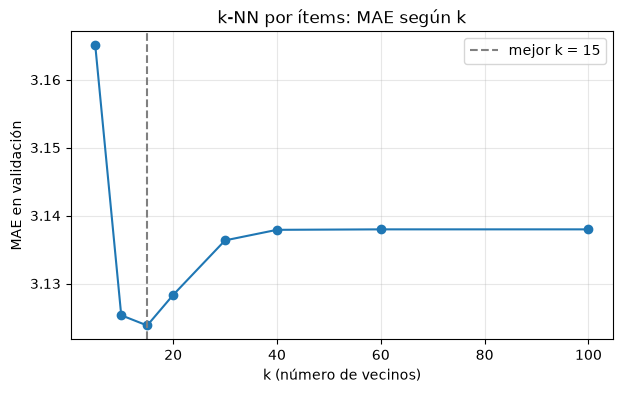

In [20]:
# Gráfica: MAE de validación según el número de vecinos k
plt.figure(figsize=(7, 4))
plt.plot(mae_por_k.index, mae_por_k.values, marker="o")
plt.axvline(mejor_k, color="gray", linestyle="--", label=f"mejor k = {mejor_k}")
plt.xlabel("k (número de vecinos)")
plt.ylabel("MAE en validación")
plt.title("k-NN por ítems: MAE según k")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Resultado:** el mejor valor es **k = 15**, que mejora claramente a los sesgos (≈ 0,35 puntos menos de MAE). Con k muy
pequeño (5) el error sube porque la media se basa en muy pocas notas. A partir de k ≈ 40 la curva se aplana: los
vecinos que se van añadiendo tienen similitud casi nula o negativa (y las negativas no cuentan), así que apenas
cambian la media.

In [21]:
# Comprobaciones del k-NN: debe mejorar a los sesgos
assert resultados["k-NN ítems"] < resultados["Sesgos"] and resultados["k-NN ítems"] < 3.20
# La matriz de similitudes real (calculada una sola vez en la celda de la rejilla): simétrica, diagonal 0, entre -1 y 1
assert np.allclose(S, S.T) and np.all(np.diag(S) == 0) and np.abs(S).max() <= 1 + 1e-5
print("k-NN mejora a los sesgos")

k-NN mejora a los sesgos


## 5. Resumen

MAE de validación de cada método y cuánto mejora respecto a la media global. Para aprobar, el enunciado pide mejorar
al menos un **15 %** la media global.

In [22]:
resumen = pd.DataFrame({"Método": list(resultados.keys()), "MAE validación": list(resultados.values())})
resumen["Mejora vs media global (%)"] = 100 * (1 - resumen["MAE validación"] / resultados["Media global"])
display(resumen.round({"MAE validación": 3, "Mejora vs media global (%)": 1}))

,Método,MAE validación,Mejora vs media global (%)
0,Media global,4.432,0.0
1,Media restaurante,4.192,5.4
2,Media usuario,3.738,15.7
3,Sesgos,3.469,21.7
4,k-NN ítems,3.124,29.5


**Guardamos las predicciones de validación** para poder comparar este método con la SVD en `comparativa.ipynb`.
Las calculamos con el modelo entrenado con `R_train` y el mejor k, es decir, las mismas predicciones que dieron el
MAE de validación de la tabla. Se guardan en `predicciones/validacion_knn.csv` (usuario, restaurante, nota real y
predicción de cada una de las 40.000 valoraciones apartadas).

In [23]:
# Predicción de las 40.000 valoraciones de validación con el mejor k (E, M, S y los sesgos aún son los de R_train)
pred_validacion = predecir_knn(E, M, S, mu, b_u, b_i, val_u, val_i, mejor_k)

os.makedirs("predicciones", exist_ok=True)       # crea la carpeta si no existe
pd.DataFrame({
    "usuario": usuarios[val_u],
    "restaurante": restaurantes[val_i],
    "real": val_real,
    "prediccion": pred_validacion,
}).to_csv("predicciones/validacion_knn.csv", sep=";", index=False, float_format="%.4f")
print(f"predicciones/validacion_knn.csv escrito: {len(pred_validacion):,} filas (k = {mejor_k})")

predicciones/validacion_knn.csv escrito: 40,000 filas (k = 15)


In [24]:
# Comprobaciones del fichero de validación (lo usa comparativa.ipynb)
val_guardada = pd.read_csv("predicciones/validacion_knn.csv", sep=";")
assert list(val_guardada.columns) == ["usuario", "restaurante", "real", "prediccion"] and len(val_guardada) == N_VALIDACION
assert (val_guardada["usuario"].values == usuarios[val_u]).all()
assert (val_guardada["restaurante"].values == restaurantes[val_i]).all()
# Es la predicción del modelo entrenado con R_train y el mejor k: mismo MAE que en la rejilla (redondeo a 4 decimales)
assert abs(mae(val_guardada["prediccion"].values, val_guardada["real"].values) - resultados["k-NN ítems"]) < 1e-3
print("validacion_knn.csv correcto")

validacion_knn.csv correcto


## 6. Predicción final

Ya hemos elegido el método (k-NN por ítems) y sus parámetros (λ y k) usando solo la validación. Ahora **volvemos a
calcularlo todo con la matriz completa `R`**, sin ocultar nada: las 40.000 valoraciones que habíamos apartado también
son información útil. Con esto predecimos las 40.000 posiciones de `template.csv`.

`resultats.csv` se escribe con el mismo orden que `template.csv`, separador `;`, sin cabecera y con **punto** decimal
(pandas usa siempre punto, independientemente de la configuración regional del ordenador).

In [25]:
# Mismos pasos que en la validación, pero ahora con R completa y los parámetros elegidos
mu, b_u, b_i = calcular_sesgos(R, mejor_lam_u, mejor_lam_i)
E, M = calcular_residuos(R, mu, b_u, b_i)
S = calcular_similitudes(E, M)
pred_final = predecir_knn(E, M, S, mu, b_u, b_i, filas_u, cols_i, mejor_k)

salida = plantilla.copy()
salida["nota"] = pred_final
salida.to_csv("resultats.csv", sep=";", header=False, index=False, float_format="%.4f")
print(f"resultats.csv escrito: {len(salida):,} predicciones (λ_u = {mejor_lam_u}, λ_i = {mejor_lam_i}, k = {mejor_k})")
display(salida.head())

resultats.csv escrito: 40,000 predicciones (λ_u = 0, λ_i = 0, k = 15)


,usuario,restaurante,nota
0,User25287,Restaurant31,-0.005422
1,User45110,Restaurant50,4.759673
2,User53493,Restaurant19,2.310256
3,User16630,Restaurant10,-0.197686
4,User48335,Restaurant8,-0.611463


In [26]:
# Comprobaciones del fichero de salida: mismo orden y formato que template.csv
leido = pd.read_csv("resultats.csv", sep=";", header=None, names=["usuario", "restaurante", "nota"])
assert len(leido) == 40000 and leido["nota"].dtype == np.float64
assert (leido["usuario"].values == plantilla["usuario"].values).all()
assert (leido["restaurante"].values == plantilla["restaurante"].values).all()
assert leido["nota"].between(-10, 10).all() and np.isfinite(pred_final).all()
print("resultats.csv correcto")

resultats.csv correcto


## 7. Comprobación oficial

Ahora, y **solo ahora**, comparamos con el test oficial. Ejecutamos el script `compute_mae.py` del enunciado (sin
modificarlo) con `target_recommendations.csv` y nuestro `resultats.csv`, igual que se haría desde la terminal:

```
python compute_mae.py ConjuntDades_P2/target_recommendations.csv resultats.csv
```

In [27]:
resultado = subprocess.run(
    [sys.executable, f"{RUTA_DATOS}/compute_mae.py", f"{RUTA_DATOS}/target_recommendations.csv", "resultats.csv"],
    capture_output=True, text=True,
)
print(resultado.stdout.strip() or resultado.stderr)

MAE: 3.132


In [28]:
# Comprobaciones de la evaluación oficial
assert resultado.returncode == 0, resultado.stdout + resultado.stderr   # el script no ha detectado errores de formato
mae_oficial = float(resultado.stdout.split()[-1])                        # la salida es "MAE: x.xxx"
assert mae_oficial < 3.77                                                # umbral para aprobar
print("Evaluación oficial correcta")

Evaluación oficial correcta


## Conclusión

- **MAE oficial (el que va al informe, con 3 decimales): el que imprime la celda de la sección 7** (en nuestra ejecución, **3,132**).
- Es muy parecido al MAE de validación del k-NN (3,124). Eso confirma que nuestro "examen de práctica" se comporta como el
  test oficial y que no hemos sobreajustado los parámetros.
- Respecto al método de referencia (media global, 4,43), el error se reduce un **≈ 29 %**, muy por encima del 15 % que
  se pide para aprobar.
- Cada paso de la escalera aporta: la media de usuario capta *quién* puntúa, los sesgos combinan *quién* y *qué
  restaurante*, y el k-NN añade los *gustos concretos* de cada usuario a partir de restaurantes parecidos.